# 📊 Kaggle Playground Series S6E11: Comprehensive EDA

- **Competition:** [Predicting Credit Card Fraud - Playground Series S6E11](https://www.kaggle.com/competitions/playground-series-s6e11)
- **Evaluation Metric:** **ROC AUC** (dự đoán xác suất `is_fraud` trong khoảng $[0, 1]$)
- **Mục tiêu giai đoạn 1:** Khám phá cấu trúc dữ liệu, phân tích mất cân bằng mẫu, kiểm tra tính đơn điệu của các đặc trưng rủi ro và định hướng kỹ thuật tạo đặc trưng (Feature Engineering) cho Giai đoạn 2.


In [2]:
import os
import sys
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Hiển thị cấu hình
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")


## 1. Thiết lập Môi trường & Nạp Dữ liệu
Notebook tự động nhận diện chạy trên **máy Local** hoặc trên **Kaggle Kernel**.


In [3]:
# Tự động nhận diện đường dẫn
KAGGLE_PATH = Path("/kaggle/input/playground-series-s6e11")
# Thư mục gốc repo (chạy được cả từ gốc repo lẫn từ trong shared/)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

if KAGGLE_PATH.exists():
    DATA_DIR = KAGGLE_PATH
    print(f"==> Đang chạy trên KAGGLE: {DATA_DIR}")
else:
    DATA_DIR = ROOT / "data"
    print(f"==> Đang chạy trên LOCAL: {DATA_DIR}")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sub_sample = pd.read_csv(DATA_DIR / "sample_submission.csv")


==> Đang chạy trên LOCAL: /home/hung/code/Predicting-Credit-Card-Fraud/data


## 2. Xem tổng quan dataset

In [4]:
train_df.shape, test_df.shape

((699960, 26), (299984, 25))

In [5]:
train_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [6]:
test_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,21,3,22.1,0,Fuel,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,9,1,25.1,0,Travel,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,2,4,52.9,1,Gaming,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,8,5,35.4,0,Streaming,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,14,5,44.5,0,Groceries,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


In [7]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [8]:
train_df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


## 2. Missing Values & Datatype

In [12]:
train_nulls = train_df.isnull().sum()
test_nulls = test_df.isnull().sum()

print("Số lượng missing values trong tập Train:", (train_nulls > 0).sum())
print("Số lượng missing values trong tập Test :", (test_nulls > 0).sum())

Số lượng missing values trong tập Train: 0
Số lượng missing values trong tập Test : 0


In [19]:
numeric_cols = [c for c in train_df.select_dtypes(include=[np.number]).columns if c not in ["id", "is_fraud"]]
bool_cols = train_df.select_dtypes(include=[bool]).columns.tolist()
cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()

print(f"* Numerical features ({len(numeric_cols)}): {numeric_cols}")
print(f"* Boolean risk flags ({len(bool_cols)}): {bool_cols}")
print(f"* Categorical features ({len(cat_cols)}): {cat_cols}")

* Numerical features (13): ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
* Boolean risk flags (6): ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
* Categorical features (5): ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


/tmp/ipykernel_144949/3464982344.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()


## 3. Duplicate check

In [1]:
train_df.duplicated().sum(), test_df.duplicated().sum()

NameError: name 'train_df' is not defined

## 4. Class distribution


Hợp lệ (0): 688,271 mẫu (98.33%)
Gian lận (1): 11,689 mẫu (1.67%)
Tỷ lệ mất cân bằng: 1 gian lận trên mỗi 58 giao dịch hợp lệ.


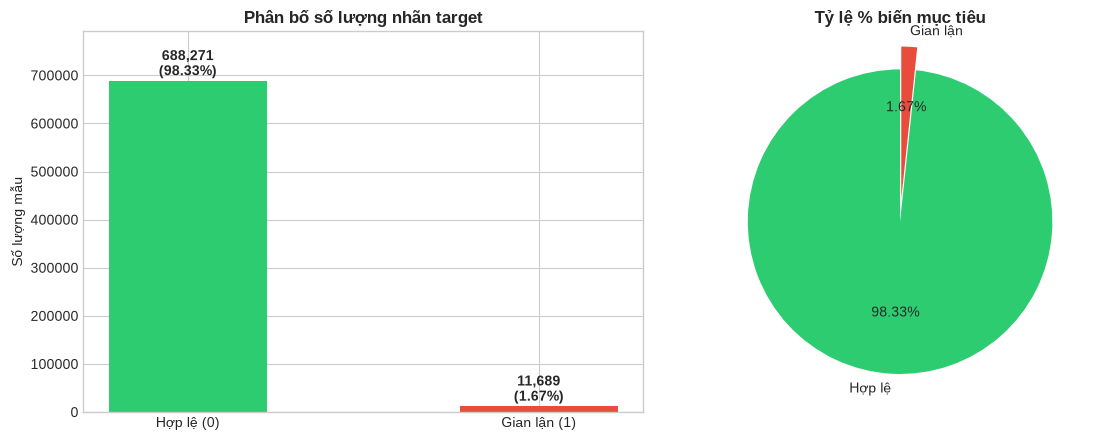

In [18]:
target_counts = train_df["is_fraud"].value_counts()
target_pct = train_df["is_fraud"].value_counts(normalize=True) * 100

print(f"Hợp lệ (0): {target_counts[0]:,} mẫu ({target_pct[0]:.2f}%)")
print(f"Gian lận (1): {target_counts[1]:,} mẫu ({target_pct[1]:.2f}%)")
print(f"Tỷ lệ mất cân bằng: 1 gian lận trên mỗi {int(target_counts[0]/target_counts[1])} giao dịch hợp lệ.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ["#2ecc71", "#e74c3c"]
ax1.bar(["Hợp lệ (0)", "Gian lận (1)"], target_counts.values, color=colors, width=0.45)
for i, v in enumerate(target_counts.values):
    ax1.text(i, v + 12000, f"{v:,}\n({v/len(train_df):.2%})", ha="center", fontweight="bold")
ax1.set_title("Phân bố số lượng nhãn target", fontsize=12, fontweight="bold")
ax1.set_ylabel("Số lượng mẫu")
ax1.set_ylim(0, max(target_counts.values) * 1.15)

ax2.pie(target_counts.values, labels=["Hợp lệ", "Gian lận"], autopct="%1.2f%%", colors=colors, explode=(0, 0.15), startangle=90)
ax2.set_title("Tỷ lệ % biến mục tiêu", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Phân tích Các Cờ Rủi Ro Boolean (Risk Flags & Fraud Lift)
Bộ dữ liệu cung cấp 6 cờ boolean thể hiện các dấu hiệu rủi ro cao:
- `is_foreign_transaction`: Giao dịch ở nước ngoài
- `ip_country_mismatch`: Quốc gia IP không khớp với thẻ
- `billing_shipping_mismatch`: Địa chỉ thanh toán khác địa chỉ giao hàng
- `is_ai_generated_scam_attempt`: Dấu hiệu lừa đảo tự động hóa / AI
- `used_vpn`: Sử dụng mạng riêng ảo VPN
- `is_new_merchant`: Giao dịch lần đầu với đơn vị bán hàng này


,Feature,True Count,Fraud Rate when True (%),Fraud Rate when False (%),Lift (Lần)
3,ip_country_mismatch,"11,312",16.50%,1.43%,11.6x
5,is_ai_generated_scam_attempt,"2,299",15.22%,1.63%,9.4x
4,billing_shipping_mismatch,"9,054",12.99%,1.52%,8.5x
0,is_foreign_transaction,"12,098",12.57%,1.48%,8.5x
2,used_vpn,"23,665",6.55%,1.50%,4.4x
1,is_new_merchant,"106,720",4.73%,1.12%,4.2x


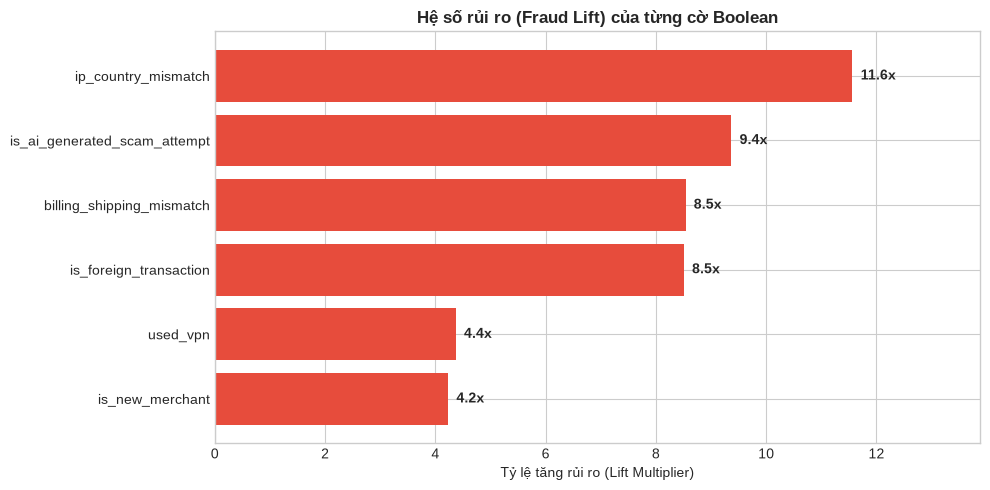

In [5]:
risk_stats = []
for c in bool_cols:
    t_rate = train_df[train_df[c] == True]["is_fraud"].mean() * 100
    f_rate = train_df[train_df[c] == False]["is_fraud"].mean() * 100
    lift = t_rate / (f_rate if f_rate > 0 else 1e-5)
    t_cnt = train_df[c].sum()
    risk_stats.append({
        "Feature": c,
        "True Count": f"{t_cnt:,}",
        "Fraud Rate when True (%)": f"{t_rate:.2f}%",
        "Fraud Rate when False (%)": f"{f_rate:.2f}%",
        "Lift (Lần)": f"{lift:.1f}x",
        "lift_val": lift
    })

risk_df = pd.DataFrame(risk_stats).sort_values("lift_val", ascending=False)
display(risk_df.drop(columns=["lift_val"]))

# Vẽ biểu đồ Lift
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = pd.DataFrame(risk_stats).sort_values("lift_val", ascending=True)
bars = ax.barh(plot_df["Feature"], plot_df["lift_val"], color="#e74c3c")
for b in bars:
    ax.text(b.get_width() + 0.15, b.get_y() + b.get_height()/2, f"{b.get_width():.1f}x", va="center", fontweight="bold")
ax.set_title("Hệ số rủi ro (Fraud Lift) của từng cờ Boolean", fontsize=12, fontweight="bold")
ax.set_xlabel("Tỷ lệ tăng rủi ro (Lift Multiplier)")
ax.set_xlim(0, max(plot_df["lift_val"]) * 1.2)
plt.tight_layout()
plt.show()


## 5. Phân tích Các Biến Định Tính (Categorical Features)
Khám phá tỷ lệ gian lận theo `merchant_category`, `auth_method`, `channel`, `card_type`, `device_type`.


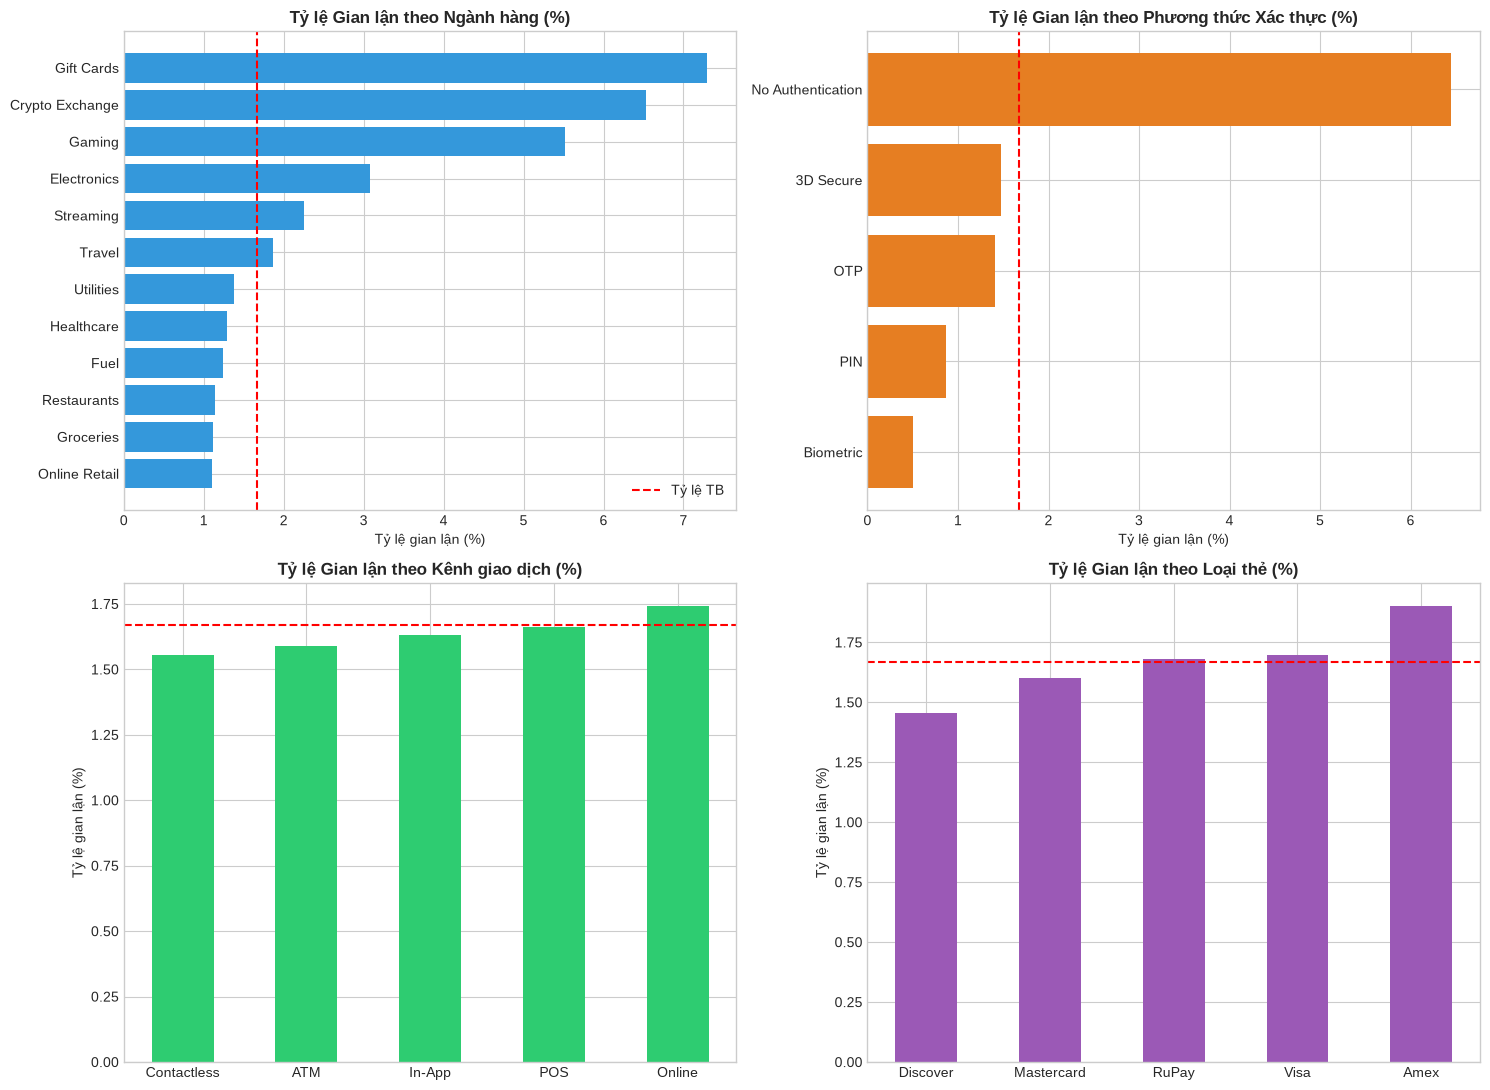

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Merchant Category
cat_summary = train_df.groupby("merchant_category")["is_fraud"].agg(["count", "mean"]).sort_values("mean", ascending=True)
axes[0, 0].barh(cat_summary.index, cat_summary["mean"] * 100, color="#3498db")
axes[0, 0].axvline(train_df["is_fraud"].mean() * 100, color="red", linestyle="--", label="Tỷ lệ TB")
axes[0, 0].set_title("Tỷ lệ Gian lận theo Ngành hàng (%)", fontweight="bold")
axes[0, 0].set_xlabel("Tỷ lệ gian lận (%)")
axes[0, 0].legend()

# 2. Auth Method
auth_summary = train_df.groupby("auth_method")["is_fraud"].agg(["count", "mean"]).sort_values("mean", ascending=True)
axes[0, 1].barh(auth_summary.index, auth_summary["mean"] * 100, color="#e67e22")
axes[0, 1].axvline(train_df["is_fraud"].mean() * 100, color="red", linestyle="--")
axes[0, 1].set_title("Tỷ lệ Gian lận theo Phương thức Xác thực (%)", fontweight="bold")
axes[0, 1].set_xlabel("Tỷ lệ gian lận (%)")

# 3. Channel
ch_summary = train_df.groupby("channel")["is_fraud"].agg(["count", "mean"]).sort_values("mean", ascending=True)
axes[1, 0].bar(ch_summary.index, ch_summary["mean"] * 100, color="#2ecc71", width=0.5)
axes[1, 0].axhline(train_df["is_fraud"].mean() * 100, color="red", linestyle="--")
axes[1, 0].set_title("Tỷ lệ Gian lận theo Kênh giao dịch (%)", fontweight="bold")
axes[1, 0].set_ylabel("Tỷ lệ gian lận (%)")

# 4. Card Type
card_summary = train_df.groupby("card_type")["is_fraud"].agg(["count", "mean"]).sort_values("mean", ascending=True)
axes[1, 1].bar(card_summary.index, card_summary["mean"] * 100, color="#9b59b6", width=0.5)
axes[1, 1].axhline(train_df["is_fraud"].mean() * 100, color="red", linestyle="--")
axes[1, 1].set_title("Tỷ lệ Gian lận theo Loại thẻ (%)", fontweight="bold")
axes[1, 1].set_ylabel("Tỷ lệ gian lận (%)")

plt.tight_layout()
plt.show()


## 6. Phân tích Biến Định Lượng (Numerical Features) & Phân Phối
Đặc biệt chú ý các thuộc tính có tương quan mạnh nhất: `cvv_retry_count`, `merchant_risk_score`, `velocity_score`, `amount_usd`.


,mean,std,min,25%,50%,75%,max
amount_usd,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


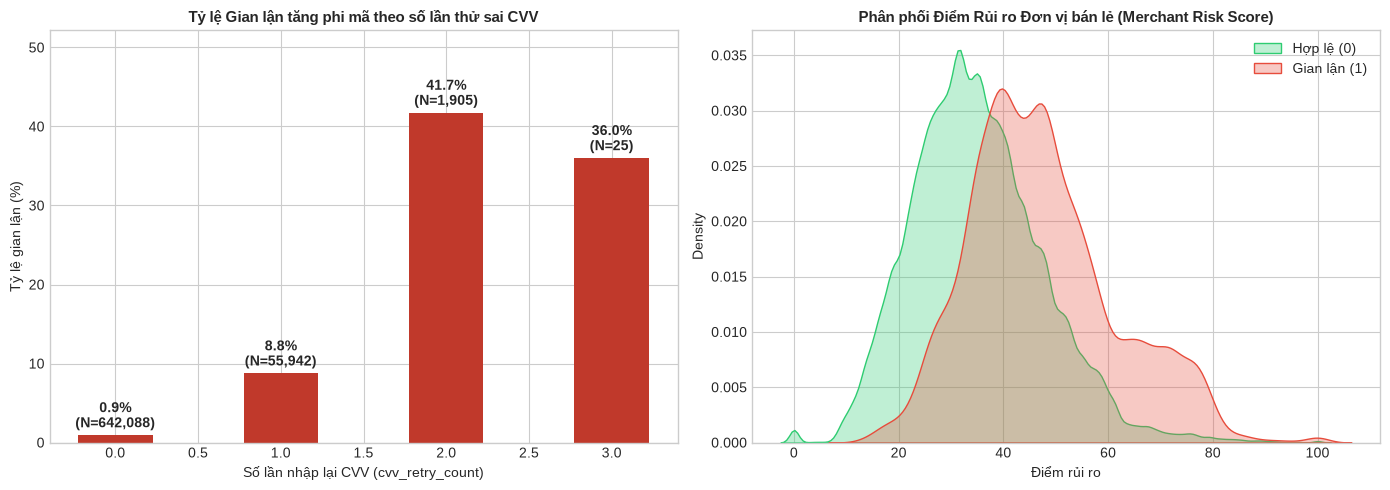

In [7]:
# Bảng thống kê mô tả
num_desc = train_df[numeric_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
display(num_desc)

# Phân tích CVV Retry Count
cvv_analysis = train_df.groupby("cvv_retry_count")["is_fraud"].agg(["count", "mean"])
cvv_analysis["fraud_rate_pct"] = cvv_analysis["mean"] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(cvv_analysis.index, cvv_analysis["fraud_rate_pct"], color="#c0392b", width=0.45)
for i, r in cvv_analysis.iterrows():
    ax1.text(i, r["fraud_rate_pct"] + 1, f"{r['fraud_rate_pct']:.1f}%\n(N={int(r['count']):,})", ha="center", fontweight="bold")
ax1.set_title("Tỷ lệ Gian lận tăng phi mã theo số lần thử sai CVV", fontsize=11, fontweight="bold")
ax1.set_xlabel("Số lần nhập lại CVV (cvv_retry_count)")
ax1.set_ylabel("Tỷ lệ gian lận (%)")
ax1.set_ylim(0, max(cvv_analysis["fraud_rate_pct"]) * 1.25)

# Merchant Risk Score KDE
sns.kdeplot(data=train_df[train_df["is_fraud"]==0]["merchant_risk_score"], label="Hợp lệ (0)", ax=ax2, color="#2ecc71", fill=True, alpha=0.3)
sns.kdeplot(data=train_df[train_df["is_fraud"]==1]["merchant_risk_score"], label="Gian lận (1)", ax=ax2, color="#e74c3c", fill=True, alpha=0.3)
ax2.set_title("Phân phối Điểm Rủi ro Đơn vị bán lẻ (Merchant Risk Score)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Điểm rủi ro")
ax2.legend()
plt.tight_layout()
plt.show()


## 7. Phân tích Ma Trận Tương Quan (Correlation Matrix)
Đánh giá độ tương quan tuyến tính giữa các biến số với mục tiêu `is_fraud`.


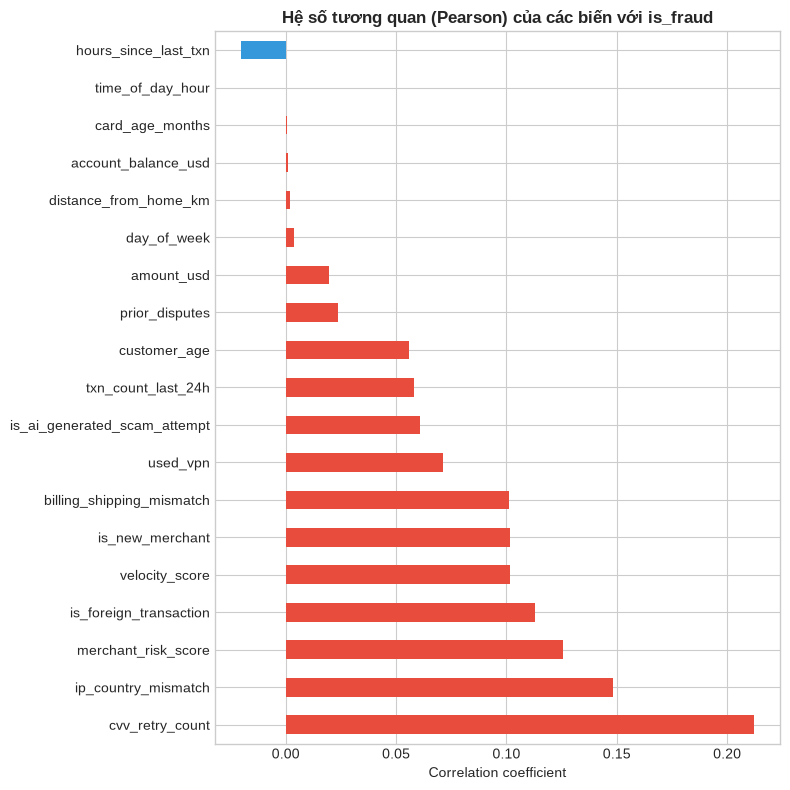

In [8]:
all_features_corr = numeric_cols + bool_cols + ["is_fraud"]
corr = train_df[all_features_corr].astype(float).corr()["is_fraud"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
corr.drop("is_fraud").plot(kind="barh", ax=ax, color=np.where(corr.drop("is_fraud") > 0, "#e74c3c", "#3498db"))
ax.set_title("Hệ số tương quan (Pearson) của các biến với is_fraud", fontsize=12, fontweight="bold")
ax.set_xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()


## 8. Kết luận EDA & Định Hướng Feature Engineering (Giai đoạn 2)

Từ kết quả khám phá dữ liệu, nhóm rút ra các kết luận trọng tâm:

1. **Tín hiệu rủi ro cực mạnh (High-impact Signals):**
   - **`cvv_retry_count`**: Khi thử sai CVV $\ge 2$ lần, tỷ lệ gian lận tăng đột biến (tương quan hàng đầu $r \approx 0.21$).
   - **Các cờ Boolean**: `ip_country_mismatch` (Lift 11.6x), `billing_shipping_mismatch` (Lift 8.5x), `is_ai_generated_scam_attempt` (Lift 9.4x), `is_foreign_transaction` (Lift 8.5x).
   - **`merchant_risk_score` & `velocity_score`**: Phân phối phân tách rõ rệt giữa hai nhóm nhãn.
   - **`auth_method`**: Các giao dịch `No Authentication` có nguy cơ gian lận cao gấp hơn 10 lần so với `Biometric` hoặc `PIN`.
   - **Ngành hàng**: `Gift Cards`, `Crypto Exchange`, `Gaming` có rủi ro cao nhất ($5 - 7.5\%$).

2. **Định hướng Feature Engineering cho Giai đoạn 2:**
   - **Risk Score tổng hợp:** Đếm số cờ rủi ro (`risk_flags_count = is_foreign + ip_mismatch + billing_mismatch + used_vpn + ...`).
   - **Tương tác đặc trưng (Interactions):** 
     - Tỷ lệ `amount_usd / account_balance_usd` (tỷ trọng số dư bị rút trong giao dịch).
     - Rủi ro kết hợp: `merchant_risk_score * velocity_score`.
     - Tốc độ giao dịch: `amount_usd / (hours_since_last_txn + 1)`.
   - **Mã hóa mục tiêu (Target Encoding) có kiểm soát Out-of-Fold:** áp dụng cho `merchant_category`, `auth_method` để khai thác triệt để phân tầng rủi ro.
   - **Tần suất giao dịch:** Tần suất theo `device_type`, `channel` theo từng khung giờ trong ngày.
